# Neighbourhood context and solar access

Represent nearby shading with explicit geometry, then compare reproducible illustrative neighbourhoods.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

`ContextBuilding` describes a neighbour's footprint and height. `ContextSpec` groups resolved neighbours, and `synthetic_context(...)` produces such an explicit group from a preset and seed. None of these objects create indoor thermal zones for the neighbours.

Use the documentation gallery to distinguish custom context from generated scenarios. The paired urban images use the same horizontal arrangement with different heights; their apparent screen scale can differ because each view fits its own extent. A neighbour can reduce direct solar access without changing the target's prescribed weather or ventilation.

### Figure guide — An explicitly supplied shading neighbour

![An explicitly supplied shading neighbour; reference figure from EPSM documentation](../../docs/figures/viewer-custom.png)

**How to read this figure.** The documentation example supplies one 18 m neighbour beside a 9 m target. Its position and dimensions are inputs, rather than a generated density label. The picture shows shading geometry only, not a thermally coupled adjacent building.

*Source: [EPSM geometry documentation](../../docs/geometry.md); [open the original figure](../../docs/figures/viewer-custom.png).*

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Provide a custom neighbour

Context objects shade the target but are not thermally coupled. A courtyard can contain a neighbour; positive-area overlap with target footprints is rejected.

### Read the code and output

The custom rectangle is placed north of the target in their shared metric frame. Its identifier is retained on its shading surfaces for selection in the viewer. Boundary contact can be allowed geometrically, but a heated party-wall boundary requires a separate reviewed declaration.

### Figure guide — A seeded illustrative rural context

![A seeded illustrative rural context; reference figure from EPSM documentation](../../docs/figures/viewer-rural.png)

**How to read this figure.** This documentation screenshot has eight generated neighbours for its stated seed and settings. The actual count in the cells below can differ when their seed or target changes. Read the generation report instead of treating the picture as a required output.

*Source: [EPSM geometry documentation](../../docs/geometry.md); [open the original figure](../../docs/figures/viewer-rural.png).*

In [2]:
from shapely.geometry import box
g = geometry()
neighbour = ContextBuilding(identifier="north-neighbour",
                            footprints=(Footprint(exterior=tuple(box(5,30,25,45).exterior.coords)),),
                            height_m=18)
context = ContextSpec(buildings=(neighbour,))
table(neighbour.model_dump())
display(g.widget(context=context))

,field,value
0,identifier,north-neighbour
1,footprints,"({'exterior': ((25.0, 30.0), (25.0, 45.0), (5...."
2,height_m,18.0
3,base_elevation_m,0


## Generate seeded scenarios

The same seed makes the low-rise and high-rise horizontal geometry comparable. These presets change shading, not weather, wind or engine terrain.

### Read the code and output

The generation metadata reports what was actually achieved after clearance and overlap checks. Compare that count with your intended neighbourhood assumptions. Fixing the seed makes reruns reproducible; it does not turn the generated arrangement into a measured neighbourhood or guarantee a representative density.

### Figure guide — Illustrative dense low-rise surroundings

![Illustrative dense low-rise surroundings; reference figure from EPSM documentation](../../docs/figures/viewer-urban_lowrise_dense.png)

**How to read this figure.** This reference scene contains 25 neighbours. Compare their footprints with the high-rise counterpart: the horizontal pattern is shared for matched generation settings, making height the intended difference. Each image fits its own scene, so apparent pixel scale is not a metric comparison.

*Source: [EPSM geometry documentation](../../docs/geometry.md); [open the original figure](../../docs/figures/viewer-urban_lowrise_dense.png).*

,preset,seed,radius_m,clearance_m,spacing_m,size_range_m,height_range_m,max_buildings,candidate_count,generated_building_count,supplied_building_count,achieved_building_count,assumption
0,rural,17,100.0,20.0,64.0,"[10.0, 18.0]","[3.0, 9.0]",128,9,8,0,8,Illustrative geometric shading scenario; not a...
1,urban_lowrise_dense,17,100.0,10.0,32.0,"[20.0, 26.0]","[6.0, 15.0]",128,29,24,0,24,Illustrative geometric shading scenario; not a...
2,urban_highrise_dense,17,100.0,10.0,32.0,"[20.0, 26.0]","[24.0, 60.0]",128,29,24,0,24,Illustrative geometric shading scenario; not a...


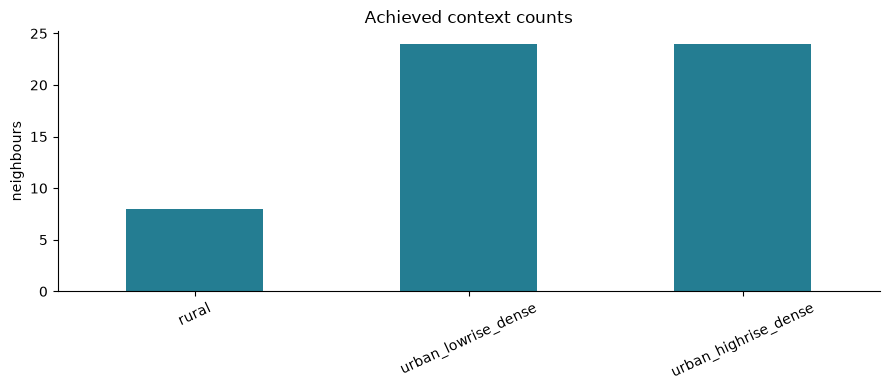

In [3]:
contexts = {name: synthetic_context(g, preset=name, seed=17) for name in ["rural","urban_lowrise_dense","urban_highrise_dense"]}
for name,c in contexts.items():
    display(g.widget(context=c, height=450))
table([{ "preset": name, **c.generation} for name,c in contexts.items()])
bars({name:len(c.buildings) for name,c in contexts.items()}, "neighbours", "Achieved context counts")

## Inspect target and context separately

Cutaway controls affect the target while retaining complete neighbour silhouettes. Keep the achieved context count and representation assumptions with your study.

### Read the code and output

Use cutaway to see the target's internals while keeping neighbour silhouettes complete. The final assertion isolates the intended high-rise/low-rise height comparison by confirming their footprints agree. The context sensitivity chart in the documentation reports separate retained runs, not the energy outcome of this geometry-only notebook.

### Figure guide — Illustrative dense high-rise surroundings

![Illustrative dense high-rise surroundings; reference figure from EPSM documentation](../../docs/figures/viewer-urban_highrise_dense.png)

**How to read this figure.** The high-rise counterpart raises neighbours while retaining the matched horizontal pattern. Complete roof caps help assess their shading silhouette. The preset does not also change EPW weather, wind exposure or EnergyPlus terrain.

*Source: [EPSM geometry documentation](../../docs/geometry.md); [open the original figure](../../docs/figures/viewer-urban_highrise_dense.png).*

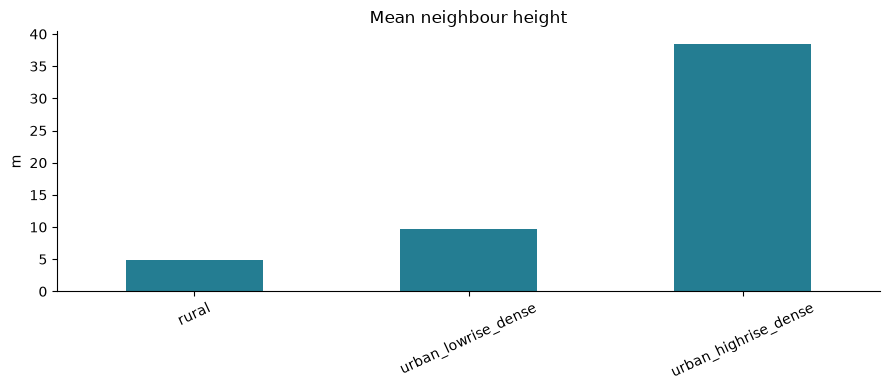

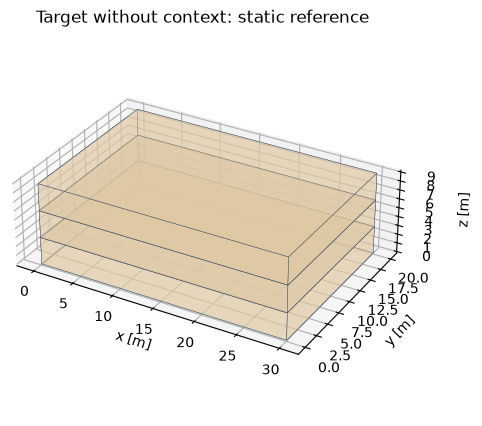

In [4]:
heights = {name:np.mean([n.height_m for n in c.buildings]) for name,c in contexts.items()}
bars(heights, "m", "Mean neighbour height")
assert [n.footprints for n in contexts["urban_lowrise_dense"].buildings] == [n.footprints for n in contexts["urban_highrise_dense"].buildings]
preview(g, "Target without context: static reference", interactive=False)

## Interpretation and next experiment

Use matched target inputs to assess shading sensitivity. Do not interpret the labels rural or urban as complete environmental boundary conditions.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.